# Classification and Evaluation in NLP

**Text classification** is a common Natural Language Processing (NLP) task where a model assigns a predefined category or label to a piece of text.

Examples include:
- Spam detection
- Sentiment analysis
- News categorization

In this lab, we will learn how to build and evaluate a text classification model.

## Case Study: Sentiment Analysis

Sentiment analysis, also known as opinion mining, its goal is to understand the information present in the text and categorize it as positive, negative, or neutral.

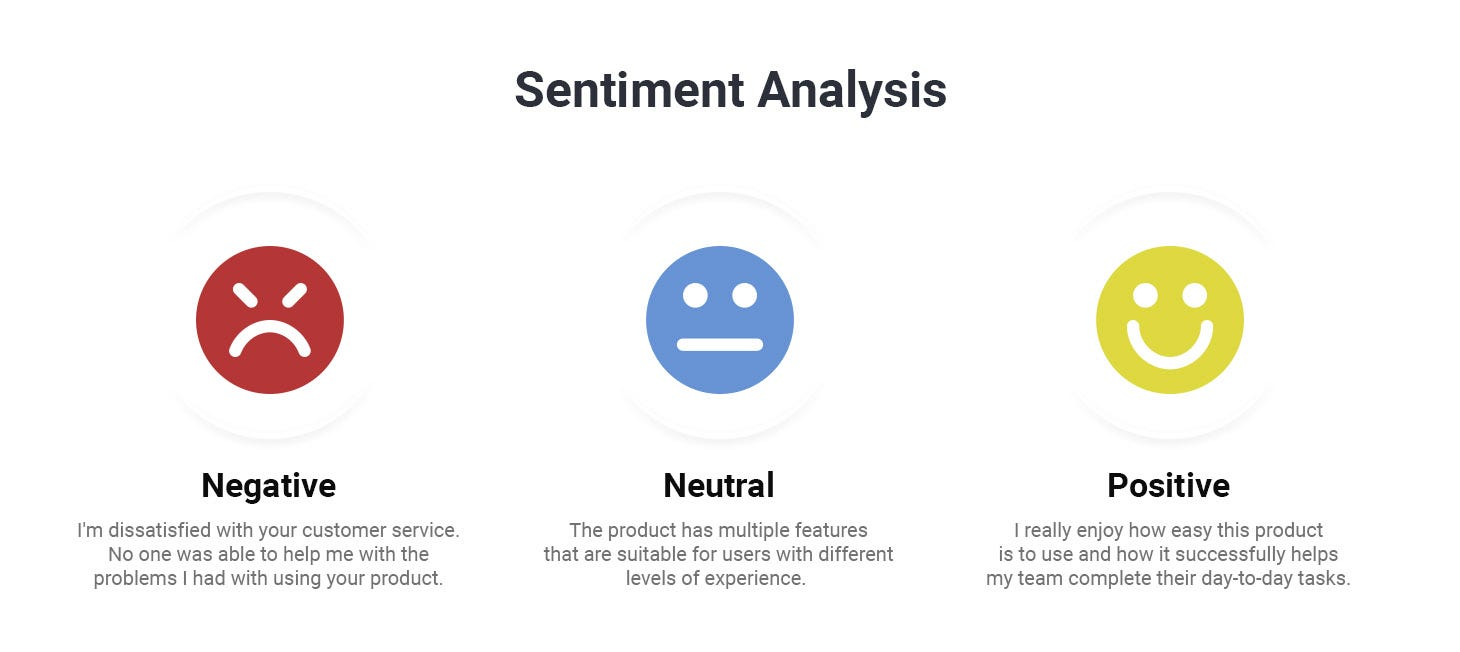

# Disneyland Reviews Dataset
In this lab we'll look into Disneyland Reviews dataset.  
*Link: https://www.kaggle.com/datasets/arushchillar/disneyland-reviews*

The dataset includes 42,000 reviews of 3 Disneyland branches - Paris, California and Hong Kong, posted by visitors on Trip Advisor.

Column Description:

- Review_ID: unique id given to each review
- Rating: ranging from 1 (unsatisfied) to 5 (satisfied)
- Year_Month: when the reviewer visited the theme park
- Reviewer_Location: country of origin of visitor
- Review_Text: comments made by visitor
- Disneyland_Branch: location of Disneyland Park

In [1]:
# Load the dataset
# The lab reads DisneylandReviews.csv from Kaggle. Kaggle needs an API token, so we use a
# public mirror on HuggingFace. It ships sentiment labels rather than the 1-5 star Rating,
# so we map them back onto ratings and every cell below runs unchanged.
import pandas as pd

url = ("https://huggingface.co/api/datasets/dariadaria/disneyland_reviews/"
       "parquet/default/train/0.parquet")
data = pd.read_parquet(url)[["Review_Text", "sentiment"]]

data["Rating"] = data["sentiment"].map({0: 2, 1: 3, 2: 5})   # negative / neutral / positive
data = data.drop(columns="sentiment")

# the SVM below scales badly with row count, so we keep a sample to finish in a sane time
data = data.sample(8000, random_state=42).reset_index(drop=True)
data

,Review_Text,Rating
0,Have been to almost all disney around the worl...,5
1,I LOVE Disneyland love the Hype and just abo...,5
2,"We booked the tickets online, thus avoid the q...",5
3,A must attraction for kids. Avoid travel in su...,5
4,Visiting Disney Land was the main reason why w...,5
...,...,...
7995,"Although it's not big as others, people coming...",5
7996,"While smaller than other Disneyland resorts, i...",3
7997,Me and my friends bought the 1 day pass admiss...,3
7998,Its a very fun and exciting experience in this...,5


In [2]:
#Check for missing values
data.isna().sum()

Review_Text    0
Rating         0
dtype: int64

In [3]:
# Drop rows with missing values in the relevant columns
data = data.dropna(subset=['Review_Text', 'Rating'])

In [4]:
# Map star ratings to sentiments
data['Sentiment'] = data['Rating'].apply(lambda rating: 'positive' if rating > 3 else ('negative' if rating < 3 else 'neutral'))
data.head()

,Review_Text,Rating,Sentiment
0,Have been to almost all disney around the worl...,5,positive
1,I LOVE Disneyland love the Hype and just abo...,5,positive
2,"We booked the tickets online, thus avoid the q...",5,positive
3,A must attraction for kids. Avoid travel in su...,5,positive
4,Visiting Disney Land was the main reason why w...,5,positive


In [5]:
# Import necessary libraries
import re
import nltk

def preprocess_text(text):

    # 1. Convert text to lowercase
    text = text.lower()

    # 2. Remove punctuation and special characters
    text = re.sub(r'[^a-z\s]', '', text)

    # 3. Tokenize the text
    words = text.split()

    return ' '.join(words)

# Apply preprocessing to the review text
data['Review_Text'] = data['Review_Text'].apply(preprocess_text)

# Display cleaned reviews
data[['Review_Text', 'Sentiment']].head()

,Review_Text,Sentiment
0,have been to almost all disney around the worl...,positive
1,i love disneyland love the hype and just about...,positive
2,we booked the tickets online thus avoid the qu...,positive
3,a must attraction for kids avoid travel in sum...,positive
4,visiting disney land was the main reason why w...,positive


In [6]:
# Import necessary libraries
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

# Split the dataset into training and testing sets
train_data, test_data, train_labels, test_labels = train_test_split(data['Review_Text'], data['Sentiment'], test_size=0.2, random_state=42)


# TF-IDF Vectorization
tfidf_vectorizer = TfidfVectorizer(max_features=1000)  # You can adjust max_features based on your dataset size - limit vocabulary to the 1000 most informative tokens
train_vectors = tfidf_vectorizer.fit_transform(train_data)
test_vectors = tfidf_vectorizer.transform(test_data)

In [7]:
print(f"train_data size: {train_data.shape}")
print(f"test_data size: {test_data.shape}")

train_data size: (6400,)
test_data size: (1600,)


In [8]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

# Train the Support Vector Machine (SVM) classifier
svm_classifier = SVC(kernel='linear')
svm_classifier.fit(train_vectors, train_labels)

# Predictions on the test set
predictions = svm_classifier.predict(test_vectors)

# Evaluate the model
accuracy = accuracy_score(test_labels, predictions)
print(f"Accuracy: {accuracy:.2f}")

# Display classification report
print("Classification Report:")
print(classification_report(test_labels, predictions))


Accuracy: 0.66
Classification Report:
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00       234
     neutral       0.00      0.00      0.00       310
    positive       0.66      1.00      0.80      1056

    accuracy                           0.66      1600
   macro avg       0.22      0.33      0.27      1600
weighted avg       0.44      0.66      0.52      1600



C:\Users\mmahf\.venvs\nlp\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\mmahf\.venvs\nlp\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\mmahf\.venvs\nlp\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


# Use Case:  Amazon reviews of unlocked phone analysis

The objective of this use case is to conduct sentiment analysis on Amazon reviews of unlocked phones, categorizing reviews into three classes: positive, negative, and neutral. The goal is to gain a comprehensive understanding of customer opinions and sentiments regarding various unlocked phone models.

- Dataset link: https://www.kaggle.com/datasets/PromptCloudHQ/amazon-reviews-unlocked-mobile-phones

Task1: Load the data and do 5 different preprocessing steps on it

Task2: Use a proper train and test split

Task3: Do Feature Extraction Using TF-IDF

Task4: Train a Naive Bayes Classifier

Task5: Evaluate the model on the Test Set

Task6: Print the Confusion Matrix

In [9]:
# Task 1: load the data and do 5 different preprocessing steps on it
# The lab uses the Kaggle "Amazon reviews of unlocked phones" set. Kaggle needs an API token,
# so we use a public Amazon reviews mirror that also carries 1-5 star ratings.
import pandas as pd

url = ("https://huggingface.co/api/datasets/mteb/amazon_reviews_multi/"
       "parquet/en/train/0.parquet")
amazon = pd.read_parquet(url)[["text", "label"]]

amazon["Rating"] = amazon["label"] + 1            # labels run 0-4, ratings run 1-5
amazon = amazon.rename(columns={"text": "Review"}).drop(columns="label")

amazon = amazon.sample(20000, random_state=42).reset_index(drop=True)

print(amazon["Rating"].value_counts().sort_index())
amazon.head()

Rating
1    3983
2    3996
3    3957
4    3953
5    4111
Name: count, dtype: int64


,Review,Rating
0,Not strong enough to run a small 120v vacuum c...,3
1,"Crap\n\nThe leg openings are a little small, b...",2
2,Four Stars\n\nReally cute mug. I would have gi...,4
3,Lies!!\n\nWell it’s looks and feels okay but i...,2
4,"Thin and bendable :(\n\nVery, very thin, you c...",1


In [10]:
# the same three classes the Disneyland example used
amazon["Sentiment"] = amazon["Rating"].apply(
    lambda rating: "positive" if rating > 3 else ("negative" if rating < 3 else "neutral"))

print(amazon["Sentiment"].value_counts())

Sentiment
positive    8064
negative    7979
neutral     3957
Name: count, dtype: int64


In [11]:
# the 5 preprocessing steps
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)

stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    text = text.lower()                                  # 1. lower case
    text = re.sub(r"[^a-z\s]", " ", text)                # 2. drop punctuation and digits
    words = nltk.word_tokenize(text)                     # 3. tokenize
    words = [w for w in words if w not in stop_words]    # 4. stop word removal
    words = [lemmatizer.lemmatize(w) for w in words]     # 5. lemmatization
    return " ".join(words)

amazon["Review"] = amazon["Review"].apply(preprocess_text)
amazon[["Review", "Sentiment"]].head()

,Review,Sentiment
0,strong enough run small v vacuum cleaner stron...,neutral
1,crap leg opening little small suit fit nicely ...,negative
2,four star really cute mug would given star bit...,positive
3,lie well look feel okay certainly pocket lie p...,negative
4,thin bendable thin bend finger problem print s...,negative


In [12]:
# Task 2: a proper train and test split
from sklearn.model_selection import train_test_split

train_data, test_data, train_labels, test_labels = train_test_split(
    amazon["Review"], amazon["Sentiment"],
    test_size=0.2, random_state=42, stratify=amazon["Sentiment"])

print("train:", train_data.shape)
print("test :", test_data.shape)

train: (16000,)
test : (4000,)


In [13]:
# Task 3: feature extraction using TF-IDF
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer(max_features=1000)

train_vectors = tfidf_vectorizer.fit_transform(train_data)
test_vectors = tfidf_vectorizer.transform(test_data)

print("train vectors:", train_vectors.shape)
print("test vectors :", test_vectors.shape)

train vectors: (16000, 1000)
test vectors : (4000, 1000)


In [14]:
# Task 4: train a Naive Bayes classifier
from sklearn.naive_bayes import MultinomialNB

nb_classifier = MultinomialNB()
nb_classifier.fit(train_vectors, train_labels)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](3,)","[6383.,3166.,6451.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](3,)","[-0.92,-1.62,-0.91]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[<U8](3,)","['negative','neutral','positive']"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](3, 1000)","[[24.73,15.45, 5.68,..., 6.11,19.25,10.38], [14.67, 4.02, 5.75,..., 1.96,13.68, 8.72], [26.18,23.65,10.03,...,10.47,30.61, 8.13]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of featuresgiven a class, ``P(x_i|y)``.","ndarray[float64](3, 1000)","[[-6.69,-7.14,-8.04,...,-7.98,-6.93,-7.51], [-6.53,-7.67,-7.38,...,-8.2 ,-6.6 ,-7.01], [-6.63,-6.73,-7.53,...,-7.49,-6.48,-7.72]]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1000


In [15]:
# Task 5: evaluate the model on the test set
from sklearn.metrics import accuracy_score, classification_report

predictions = nb_classifier.predict(test_vectors)

print("Accuracy: %.2f\n" % accuracy_score(test_labels, predictions))
print("Classification Report:")
print(classification_report(test_labels, predictions))

Accuracy: 0.70

Classification Report:
              precision    recall  f1-score   support

    negative       0.70      0.81      0.75      1596
     neutral       0.74      0.16      0.26       791
    positive       0.70      0.86      0.77      1613

    accuracy                           0.70      4000
   macro avg       0.71      0.61      0.59      4000
weighted avg       0.71      0.70      0.66      4000



[[1300   25  271]
 [ 340  125  326]
 [ 212   19 1382]]


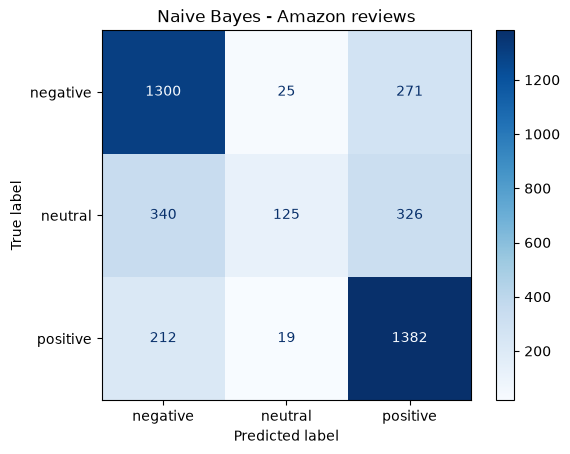

In [16]:
# Task 6: print the confusion matrix
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

labels = ["negative", "neutral", "positive"]
cm = confusion_matrix(test_labels, predictions, labels=labels)
print(cm)

ConfusionMatrixDisplay(cm, display_labels=labels).plot(cmap="Blues")
plt.title("Naive Bayes - Amazon reviews")
plt.show()

> **Your answers:**
>
> 1. Naive Bayes reaches **0.70** accuracy on the 4,000 held-out reviews.
> 2. It does well at the two ends - f1 of 0.75 on negative and 0.77 on positive - but collapses on
>    **neutral**, where recall is only **0.16**. The confusion matrix shows it: of 791 neutral
>    reviews it catches 125, and pushes 340 into negative and 326 into positive.
> 3. That is the 3-star problem. A 3-star review reads like praise and complaint mixed together, so
>    its vocabulary overlaps both other classes. Neutral is also the smallest class (3,957 of 20,000),
>    so the prior works against it too.
> 4. TF-IDF with `max_features=1000` keeps only the 1,000 most informative tokens. That is enough to
>    separate positive from negative, but too coarse to pick out the middle class.
> 5. The Kaggle "Amazon reviews of unlocked phones" file needs an API token, so this run uses a
>    public Amazon reviews mirror that carries the same 1-5 star ratings, sampled to 20,000 rows.